# Customer Clustering Project

In this project we want to divide the mall customers into different groups based on their information.
The dataset has 200 customers with these columns: CustomerID, Gender, Age, Annual Income and Spending Score.

Since we don't have any label for the customers, this is an **unsupervised** problem, so we use clustering.
We try three algorithms: **K-Means**, **Hierarchical** and **DBSCAN**, and then compare them.

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

## 2. Load the data

In [2]:
df = pd.read_csv("data/Mall_Customers.csv")
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [4]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


## 3. Data cleaning

First we rename the columns because the original names are long and have spaces in them.
Then we check for missing values and duplicate rows.

In [5]:
df.columns = ["CustomerID", "Gender", "Age", "Income", "Spending"]

print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

CustomerID    0
Gender        0
Age           0
Income        0
Spending      0
dtype: int64
Duplicates: 0


There are no missing values and no duplicates, so the data is clean.

Now we check for outliers with boxplots:

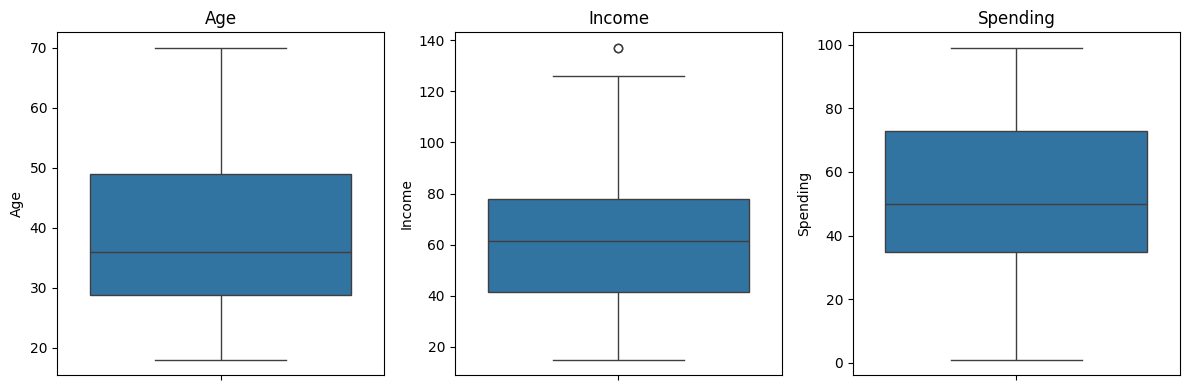

In [6]:
plt.figure(figsize=(12, 4))
for i, col in enumerate(["Age", "Income", "Spending"]):
    plt.subplot(1, 3, i + 1)
    sns.boxplot(y=df[col])
    plt.title(col)
plt.tight_layout()
plt.show()

Only Income has two outliers (137 k$). These are real customers with high income, not wrong data, so we keep them.

### Encoding Gender

Gender is text (Male/Female), so we convert it to numbers with `LabelEncoder`. Because it has only two values, LabelEncoder works fine here (Female = 0, Male = 1).

In [7]:
le = LabelEncoder()
df["Gender"] = le.fit_transform(df["Gender"])
df.head()

,CustomerID,Gender,Age,Income,Spending
0,1,1,19,15,39
1,2,1,21,15,81
2,3,0,20,16,6
3,4,0,23,16,77
4,5,0,31,17,40


## 4. Data visualization (EDA)

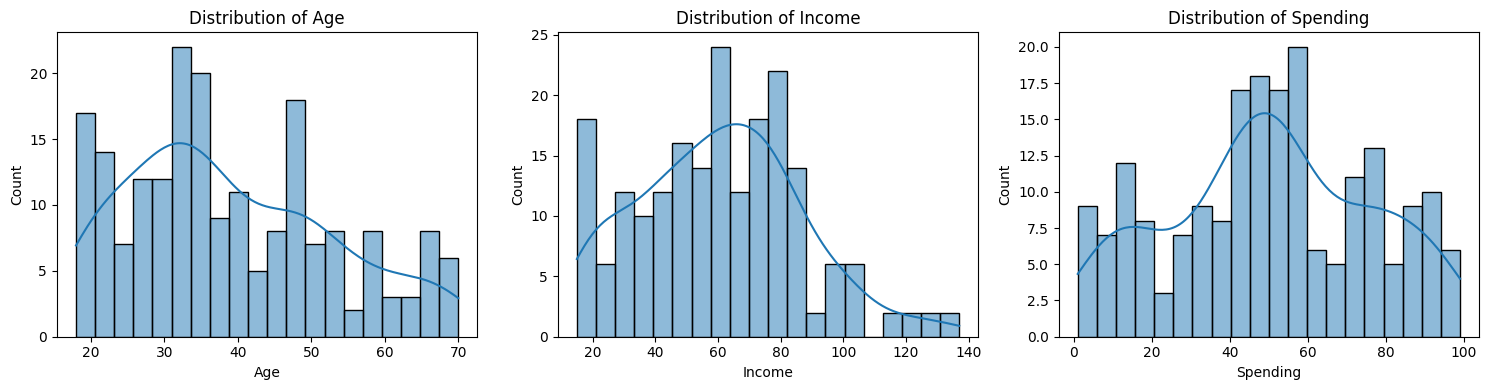

In [8]:
plt.figure(figsize=(15, 4))
for i, col in enumerate(["Age", "Income", "Spending"]):
    plt.subplot(1, 3, i + 1)
    sns.histplot(df[col], kde=True, bins=20)
    plt.title("Distribution of " + col)
plt.tight_layout()
plt.show()

- Most customers are between 20 and 40 years old.
- Income is mostly between 40 and 80 k$.
- Spending score is concentrated around 50.

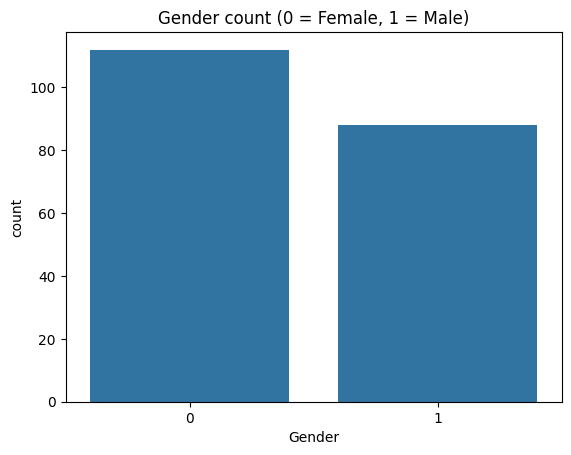

In [9]:
sns.countplot(x="Gender", data=df)
plt.title("Gender count (0 = Female, 1 = Male)")
plt.show()

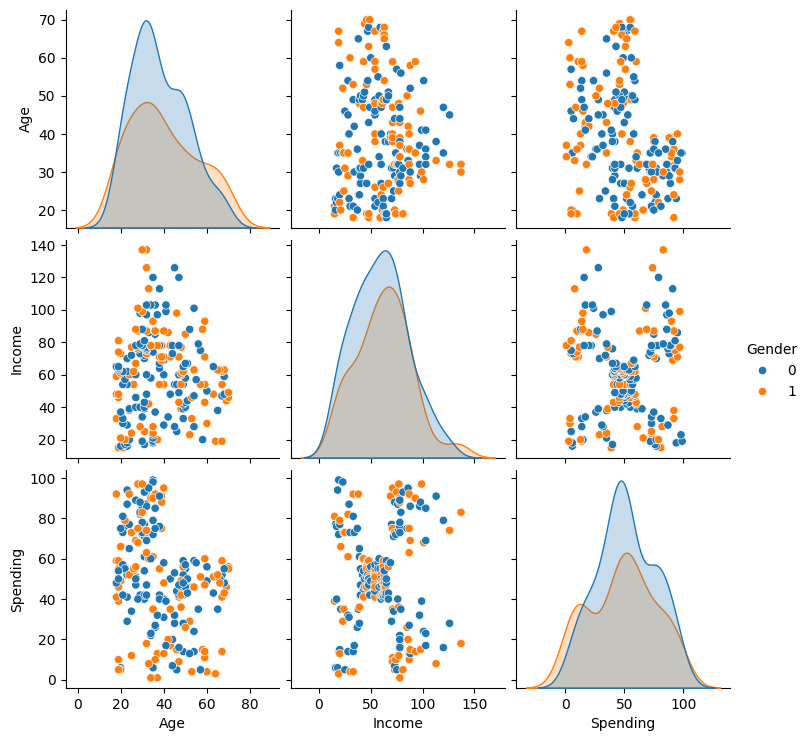

In [10]:
sns.pairplot(df.drop("CustomerID", axis=1), hue="Gender")
plt.show()

In the pairplot, the **Income vs Spending** chart clearly shows about 5 groups of customers. The other charts don't show clear groups.
Also male and female points are mixed together, so gender doesn't help much in separating the customers.

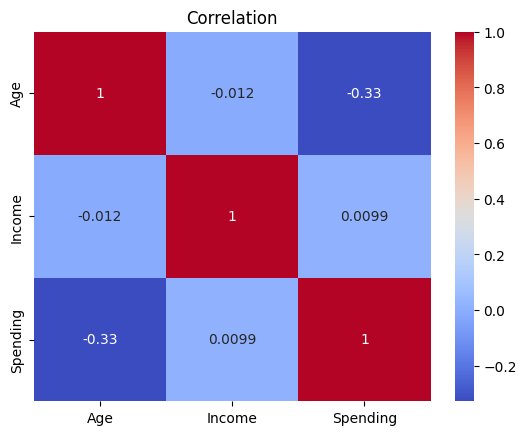

In [11]:
sns.heatmap(df[["Age", "Income", "Spending"]].corr(), annot=True, cmap="coolwarm")
plt.title("Correlation")
plt.show()

Income and Spending have almost zero correlation. Age has a small negative correlation with Spending (younger people spend a bit more).

## 5. Feature selection and scaling

- **CustomerID** is just a number for each customer, so we remove it.
- **Gender** didn't show any difference between groups, so we don't use it.
- We use **Annual Income** and **Spending Score** because they showed the clearest groups. Using two features also lets us draw the clusters in a 2D chart.

Clustering algorithms work with distances, so all features need to be on the same scale. We use `StandardScaler`, which changes every feature to mean = 0 and std = 1.
(I also tried `MinMaxScaler`, and the results were almost the same, because Income and Spending already have similar ranges.)

In [12]:
X = df[["Income", "Spending"]]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## 6. K-Means

K-Means puts every customer in the cluster with the nearest center, then moves each center to the mean of its points, and repeats until nothing changes.
We have to choose the number of clusters (k) ourselves, so we use two methods:

- **Elbow method:** we plot the WCSS (inertia) for different k values and look for the point where the curve stops falling fast.
- **Silhouette score:** shows how well each point fits its own cluster compared with other clusters (from -1 to 1, higher is better).

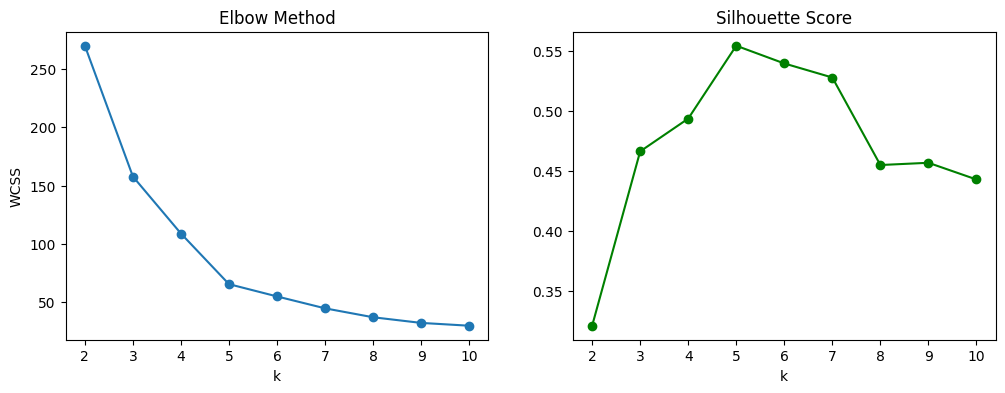

In [13]:
wcss = []
sil = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X_scaled)
    wcss.append(km.inertia_)
    sil.append(silhouette_score(X_scaled, km.labels_))

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(range(2, 11), wcss, marker="o")
plt.title("Elbow Method")
plt.xlabel("k")
plt.ylabel("WCSS")

plt.subplot(1, 2, 2)
plt.plot(range(2, 11), sil, marker="o", color="green")
plt.title("Silhouette Score")
plt.xlabel("k")
plt.show()

The elbow is at **k = 5**, and the silhouette score is also highest at k = 5. So we use 5 clusters.

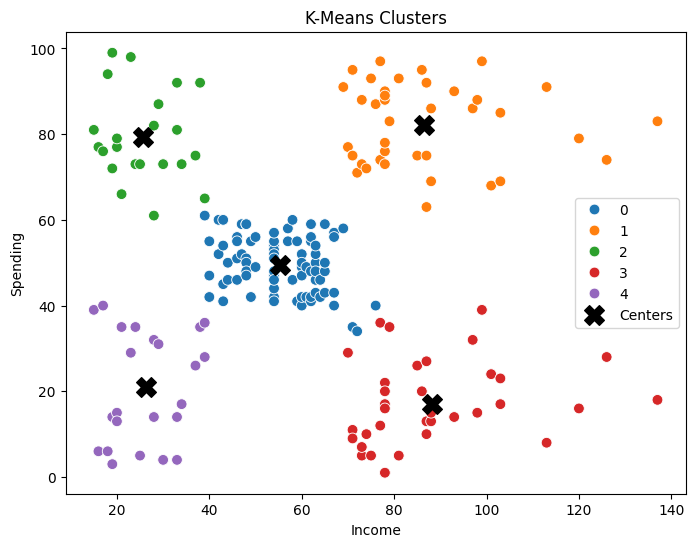

Silhouette score: 0.5546571631111091


In [14]:
kmeans = KMeans(n_clusters=5, n_init=10, random_state=42)
df["KMeans"] = kmeans.fit_predict(X_scaled)

centers = scaler.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(8, 6))
sns.scatterplot(x="Income", y="Spending", hue="KMeans", data=df, palette="tab10", s=60)
plt.scatter(centers[:, 0], centers[:, 1], c="black", marker="X", s=200, label="Centers")
plt.title("K-Means Clusters")
plt.legend()
plt.savefig("figures/result.png", dpi=150, bbox_inches="tight")
plt.show()

print("Silhouette score:", silhouette_score(X_scaled, df["KMeans"]))

## 7. Hierarchical Clustering

Hierarchical (agglomerative) clustering starts with every customer as one cluster and merges the two closest clusters again and again.
The **dendrogram** shows these merges. We can find the number of clusters by drawing a horizontal line where the vertical lines are longest.
We use **Ward** linkage, which merges the clusters that increase the variance the least.

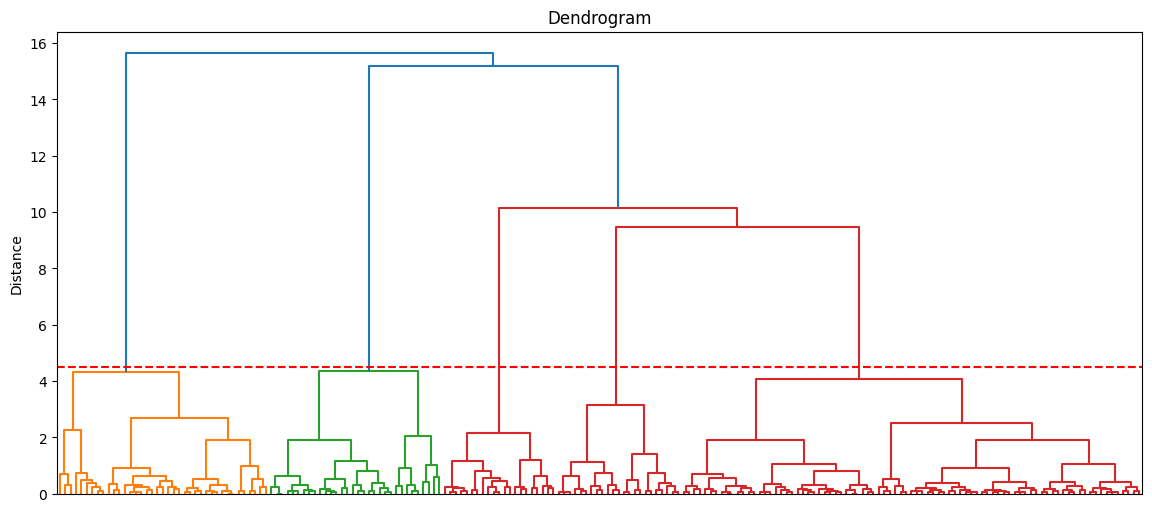

In [15]:
plt.figure(figsize=(14, 6))
dendrogram(linkage(X_scaled, method="ward"), no_labels=True)
plt.axhline(y=4.5, color="r", linestyle="--")
plt.title("Dendrogram")
plt.ylabel("Distance")
plt.show()

If we cut the dendrogram at the red line, it crosses 5 vertical lines, so the dendrogram also suggests **5 clusters**.

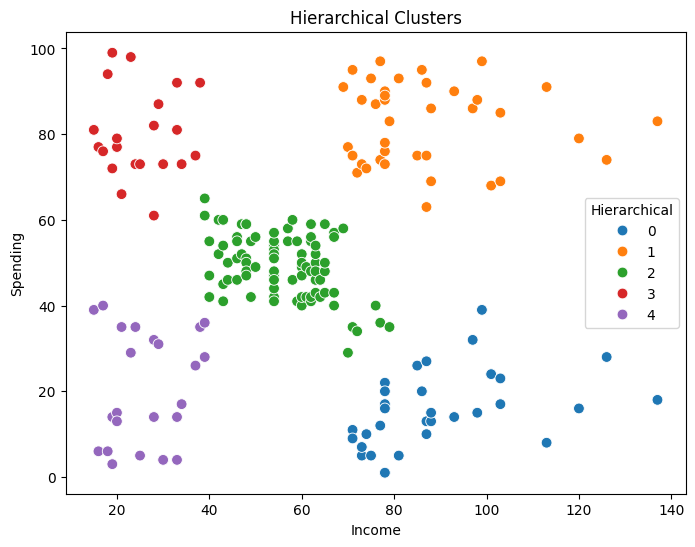

Silhouette score: 0.5538089226688662


In [16]:
hc = AgglomerativeClustering(n_clusters=5, linkage="ward")
df["Hierarchical"] = hc.fit_predict(X_scaled)

plt.figure(figsize=(8, 6))
sns.scatterplot(x="Income", y="Spending", hue="Hierarchical", data=df, palette="tab10", s=60)
plt.title("Hierarchical Clusters")
plt.show()

print("Silhouette score:", silhouette_score(X_scaled, df["Hierarchical"]))

I also tried other linkages (complete, average, single). Complete gave almost the same result, but **single** linkage was very bad because it joined almost all points into one big cluster.

In [17]:
for l in ["ward", "complete", "average", "single"]:
    labels = AgglomerativeClustering(n_clusters=5, linkage=l).fit_predict(X_scaled)
    print(l, ":", round(silhouette_score(X_scaled, labels), 3))

ward : 0.554
complete : 0.553
average : 0.479
single : 0.276


## 8. DBSCAN

DBSCAN finds clusters based on **density**. It has two parameters:
- **eps:** the radius around each point
- **min_samples:** the minimum number of points inside this radius to make a dense area

Points that are not in any dense area are labeled **-1 (noise)**. With DBSCAN we don't need to choose the number of clusters.

To find a good eps, we use the **k-distance graph**: we sort the distance of each point to its 5th nearest neighbor and look for the "knee" of the curve.

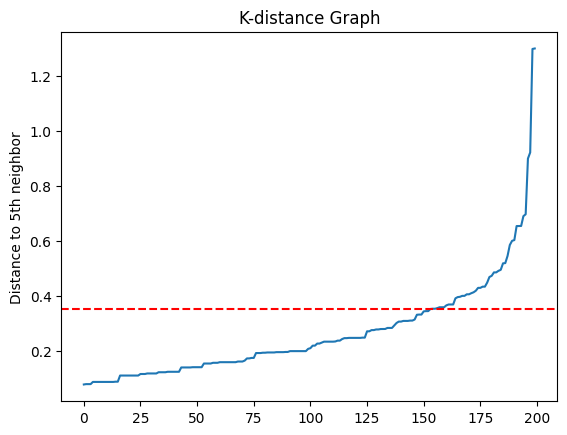

In [18]:
nn = NearestNeighbors(n_neighbors=5)
nn.fit(X_scaled)
distances, _ = nn.kneighbors(X_scaled)
distances = np.sort(distances[:, 4])

plt.plot(distances)
plt.axhline(y=0.35, color="r", linestyle="--")
plt.title("K-distance Graph")
plt.ylabel("Distance to 5th neighbor")
plt.show()

The curve starts to go up around 0.3 to 0.4. I tested some values and **eps = 0.35** with **min_samples = 5** gave the best result.

Number of clusters: 6
Noise points: 23


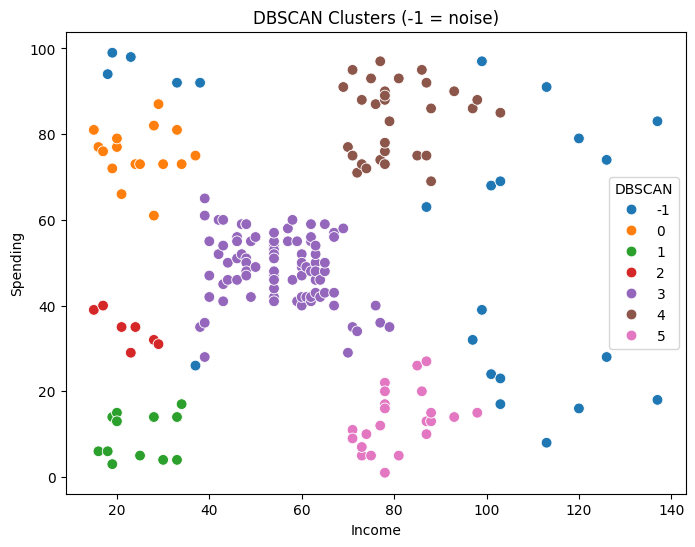

In [19]:
dbscan = DBSCAN(eps=0.35, min_samples=5)
df["DBSCAN"] = dbscan.fit_predict(X_scaled)

print("Number of clusters:", len(set(df["DBSCAN"])) - 1)
print("Noise points:", (df["DBSCAN"] == -1).sum())

plt.figure(figsize=(8, 6))
sns.scatterplot(x="Income", y="Spending", hue="DBSCAN", data=df, palette="tab10", s=60)
plt.title("DBSCAN Clusters (-1 = noise)")
plt.show()

DBSCAN found the main groups too, but it marked 23 customers at the edges as noise. It also split the low income / low spending group into two small clusters, because that group is less dense than the middle group.
So DBSCAN is not a very good choice for this data, but it's useful for finding unusual customers.

## 9. Comparing the models

In [20]:
mask = df["DBSCAN"] != -1   # we remove noise points for DBSCAN

results = pd.DataFrame({
    "Model": ["K-Means", "Hierarchical", "DBSCAN"],
    "Clusters": [5, 5, len(set(df["DBSCAN"])) - 1],
    "Silhouette": [
        silhouette_score(X_scaled, df["KMeans"]),
        silhouette_score(X_scaled, df["Hierarchical"]),
        silhouette_score(X_scaled[mask], df["DBSCAN"][mask])
    ]
})
results

,Model,Clusters,Silhouette
0,K-Means,5,0.554657
1,Hierarchical,5,0.553809
2,DBSCAN,6,0.557746


K-Means and Hierarchical have almost the same score and found almost the same groups.
DBSCAN's score looks good too, but it is calculated without the 23 noise points, so it's not a fair comparison.

**We choose K-Means** because it gives a good score, every customer gets a cluster, and the results are easy to understand.

## 10. Analyzing the clusters

Now we look at the average values in each K-Means cluster to understand what kind of customers are in it.

In [21]:
summary = df.groupby("KMeans")[["Age", "Income", "Spending"]].mean().round(1)
summary["Count"] = df["KMeans"].value_counts()
summary

,Age,Income,Spending,Count
KMeans,,,,
0,42.7,55.3,49.5,81
1,32.7,86.5,82.1,39
2,25.3,25.7,79.4,22
3,41.1,88.2,17.1,35
4,45.2,26.3,20.9,23


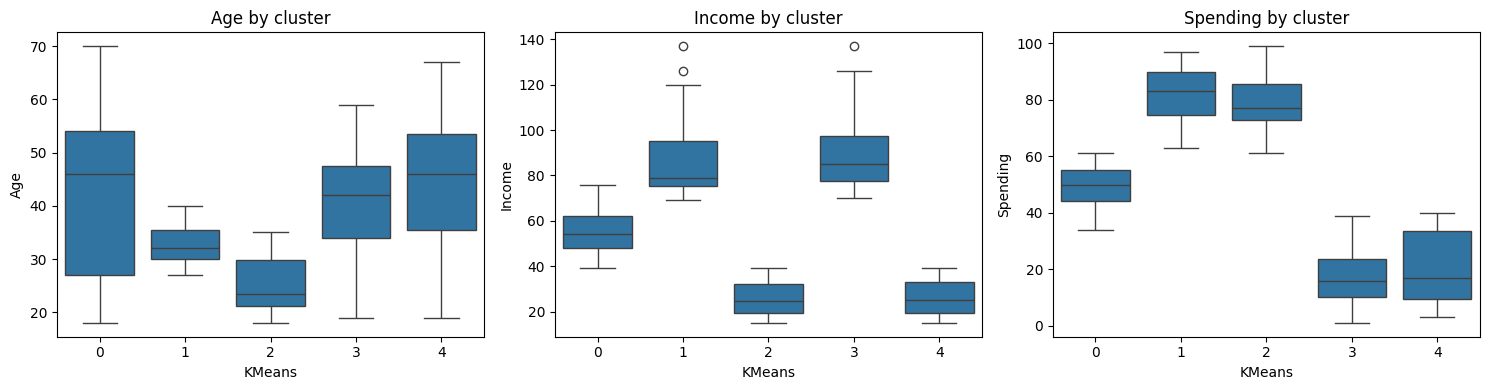

In [22]:
plt.figure(figsize=(15, 4))
for i, col in enumerate(["Age", "Income", "Spending"]):
    plt.subplot(1, 3, i + 1)
    sns.boxplot(x="KMeans", y=col, data=df)
    plt.title(col + " by cluster")
plt.tight_layout()
plt.show()

| Cluster | Description | Suggestion |
|---|---|---|
| 0 | Average income, average spending (biggest group) | General offers and campaigns |
| 1 | High income, high spending | Most valuable customers, loyalty programs and special services |
| 2 | Low income, high spending (young) | Discounts and new trendy products |
| 3 | High income, low spending | They can spend more; the mall should find out what they need |
| 4 | Low income, low spending | Cheap products and discount days |

## 11. Conclusion

- The data was clean, and we only had to rename the columns and encode Gender.
- We used Income and Spending Score with StandardScaler.
- Elbow method, silhouette score and the dendrogram all showed that **5 clusters** is the best number.
- K-Means and Hierarchical gave almost the same result (silhouette ≈ 0.55). DBSCAN was weaker for this data because the groups have different densities.
- The final model is **K-Means with 5 clusters**, and each cluster can be used for a different marketing strategy.